<a href="https://colab.research.google.com/github/jasonenkristo123/AIML-Learn/blob/main/LK01_NLP_WordVectors_Indonesia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LK01 - NLP: Word Vectors untuk Bahasa Indonesia

*Diadaptasi dari Stanford CS224n Assignment 1 (exploring word vectors) dan Assignment 2 (word2vec), disesuaikan untuk bahasa Indonesia.*

Di office hours Anda sudah melatih word2vec pada toy corpus. Minggu ini Anda melakukannya **dengan data nyata**: 11.000 ulasan berbahasa Indonesia dari **SmSA** (dataset sentimen IndoNLU), memakai objective **negative sampling** yang lebih cepat. Setelah itu, Anda menggunakan vector hasil training untuk task NLP bahasa Indonesia yang sesungguhnya, yaitu sentiment classification.

### Tujuan pembelajaran

Setelah menyelesaikan tugas ini, Anda diharapkan mampu:

1. Membangun word vector berbasis hitungan (co-occurrence → PPMI → SVD) dan menjelaskan kelemahannya.
2. Menurunkan dan mengimplementasikan loss dan gradient dari **skip-gram negative sampling**.
3. Mengeksplorasi apa yang dipelajari word vector, dan di mana ia keliru, pada teks bahasa Indonesia yang nyata.
4. Menggunakan word vector untuk downstream task, membandingkannya dengan baseline sederhana, dan menganalisis error secara jujur.

### Struktur dan penilaian

| Bagian | Isi | Poin |
|---|---|---|
| 1 | Count-based vectors: co-occurrence, PPMI, SVD | 15 |
| 2 | Soal tertulis: gradient negative sampling | 15 |
| 3 | Implementasi word2vec dengan negative sampling | 25 |
| 4 | Eksplorasi vector: nearest neighbors, analogi, antonim, bias | 15 |
| 5 | Sentiment classification bahasa Indonesia dengan word vector | 25 |
| 6 | Refleksi | 5 |
| Bonus | Salah satu pengembangan di akhir notebook | +10 |

### Aturan

* Tulis kode hanya di sel yang ditandai **`# TODO`**. Tulis jawaban di sel yang ditandai **Jawaban Anda**.
* Gunakan NumPy untuk Bagian 1–3. **Tidak boleh memakai gensim atau PyTorch**, kecuali untuk bonus.
* Setiap angka yang Anda laporkan harus berasal dari hasil run Anda sendiri. Jawaban seperti "hasilnya lebih bagus" tanpa angka tidak mendapat poin.
* Seluruh notebook berjalan sekitar 3–4 menit di CPU Colab biasa.
* Kumpulkan file `.ipynb` dengan semua output terlihat. Sebagian mahasiswa akan diminta menjelaskan kodenya dalam oral check 5 menit.

In [1]:
import os, re, time, collections, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, accuracy_score

BASE = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"

def load_split(split):
    fn = f"smsa_{split}.tsv"
    if not os.path.exists(fn):
        urllib.request.urlretrieve(BASE + f"{split}_preprocess.tsv", fn)
    rows = [l.rstrip("\n").rsplit("\t", 1) for l in open(fn, encoding="utf-8") if l.strip()]
    return [t for t, _ in rows], [lab for _, lab in rows]

train_texts, train_labels = load_split("train")
val_texts, val_labels = load_split("valid")
test_texts, test_labels = load_split("test")

for t, l in zip(train_texts[:3], train_labels[:3]):
    print(f"[{l}] {t[:120]}")
print()
for name, labs in [("train", train_labels), ("val", val_labels), ("test", test_labels)]:
    print(f"{name:5s} {len(labs):6d}  {dict(collections.Counter(labs))}")

[positive] warung ini dimiliki oleh pengusaha pabrik tahu yang sudah puluhan tahun terkenal membuat tahu putih di bandung . tahu be
[neutral] mohon ulama lurus dan k212 mmbri hujjah partai apa yang harus diwlh agar suara islam tidak pecah-pecah
[positive] lokasi strategis di jalan sumatera bandung . tempat nya nyaman terutama sofa di lantai 2 . paella nya enak , sangat pas 

train  11000  {'positive': 6416, 'neutral': 1148, 'negative': 3436}
val     1260  {'neutral': 131, 'negative': 394, 'positive': 735}
test     500  {'negative': 204, 'positive': 208, 'neutral': 88}


### Preprocessing (sudah disediakan)

Teksnya sudah dalam huruf kecil. Kita membuang token tanda baca dan hanya menyimpan kata yang muncul minimal 5 kali. Word vector hanya dilatih pada **split training**, sehingga tidak ada informasi dari kalimat validation atau test yang bocor ke dalam vector.

In [2]:
PUNCT = re.compile(r"^[^\w]+$")

def tokenize(text):
    return [w for w in text.split() if not PUNCT.match(w)]

def build_vocab(tokenized, min_count=5):
    counter = collections.Counter(w for sent in tokenized for w in sent)
    vocab = sorted(w for w, c in counter.items() if c >= min_count)
    w2i = {w: i for i, w in enumerate(vocab)}
    counts = np.array([counter[w] for w in vocab], dtype=np.float64)
    corpus_ids = [[w2i[w] for w in sent if w in w2i] for sent in tokenized]
    return vocab, w2i, counts, corpus_ids

train_tokens = [tokenize(t) for t in train_texts]
vocab, w2i, counts, corpus_ids = build_vocab(train_tokens)
V = len(vocab)
print(f"V = {V} kata, {sum(map(len, corpus_ids)):,} token training")
print("paling sering muncul:", [vocab[i] for i in np.argsort(-counts)[:15]])

def make_pairs(corpus_ids, window):
    # Fungsi yang sama dengan yang Anda tulis di office hours.
    pairs = []
    for ids in corpus_ids:
        for i, c in enumerate(ids):
            for j in range(max(0, i - window), min(len(ids), i + window + 1)):
                if j != i:
                    pairs.append((c, ids[j]))
    return np.array(pairs)

V = 4420 kata, 297,845 token training
paling sering muncul: ['nya', 'yang', 'dan', 'di', 'tidak', 'saya', 'dengan', 'makanan', 'ini', 'tempat', 'enak', 'untuk', 'makan', 'juga', 'ke']


In [3]:
# ---- Helper untuk eksplorasi vector (sudah disediakan) ----
def normalize(E):
    return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)

def nearest(E, word, w2i, vocab, k=6):
    if word not in w2i:
        return ["(not in vocab)"]
    En = normalize(E)
    sims = En @ En[w2i[word]]
    return [vocab[i] for i in np.argsort(-sims) if i != w2i[word]][:k]

def cosine(E, a, b, w2i):
    En = normalize(E)
    return float(En[w2i[a]] @ En[w2i[b]])

def analogy(E, a, b, c, w2i, vocab, k=4):
    # a : b :: c : ?
    if not all(w in w2i for w in (a, b, c)):
        return ["(not in vocab)"]
    En = normalize(E)
    sims = En @ (En[w2i[b]] - En[w2i[a]] + En[w2i[c]])
    for w in (a, b, c):
        sims[w2i[w]] = -np.inf
    return [vocab[i] for i in np.argsort(-sims)[:k]]

WORD_GROUPS = {
    "makanan": ["nasi", "ayam", "sate", "bakso", "mie", "ikan"],
    "minuman": ["kopi", "teh", "jus", "susu"],
    "tempat":  ["bandung", "jakarta", "dago", "lembang"],
    "rasa":    ["enak", "lezat", "mantap", "hambar", "asin"],
    "harga":   ["mahal", "murah"],
    "layanan": ["pelayanan", "ramah", "pelayan", "lambat"],
}
GROUP_COLORS = dict(zip(WORD_GROUPS, ["tab:green", "tab:cyan", "tab:blue", "tab:orange", "tab:red", "tab:purple"]))

def plot_words(ax, E, w2i, title):
    words = [(w, g) for g, ws in WORD_GROUPS.items() for w in ws if w in w2i]
    X = normalize(E[[w2i[w] for w, _ in words]])
    X = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(X, full_matrices=False)
    Z = X @ Vt[:2].T
    for (w, g), z in zip(words, Z):
        ax.scatter(*z, color=GROUP_COLORS[g])
        ax.annotate(w, z, fontsize=8, color=GROUP_COLORS[g], xytext=(3, 3), textcoords="offset points")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

PROBE_WORDS = ["enak", "mahal", "bandung", "pelayanan", "kecewa", "nasi", "kopi"]

---
## Bagian 1: Count-based word vectors (15 poin)

Sebelum word2vec, pendekatan standarnya adalah **menghitung**: seberapa sering kata *w* muncul di dekat context word *c*? Hasilnya adalah co-occurrence matrix $M$ berukuran V × V. Hitungan mentah didominasi oleh kata yang sangat sering muncul (*yang, di, nya*), sehingga kita memberi bobot ulang dengan **positive pointwise mutual information**:

$$\text{PPMI}(w, c) = \max\left(0,\ \log \frac{P(w, c)}{P(w)\,P(c)}\right) = \max\left(0,\ \log \frac{M_{wc} \cdot \sum M}{\left(\sum_{c'} M_{wc'}\right)\left(\sum_{w'} M_{w'c}\right)}\right)$$

PMI bertanya: *apakah w dan c muncul bersama **lebih sering daripada kebetulan**?* Kemudian setiap baris dipadatkan menjadi 100 angka dengan truncated SVD.

### 1.1 Co-occurrence matrix (5 poin)

In [4]:
def build_cooccurrence(corpus_ids, V, window=4):
    # TODO: kembalikan matriks float32 M berukuran (V, V), dengan M[c, o] = berapa kali
    # kata o muncul dalam jarak `window` posisi dari kata c.
    # Petunjuk: make_pairs memberi semua pasangan (c, o). Gunakan np.add.at untuk menghitungnya dengan cepat.
    # TULIS KODE ANDA DI SINI
  matrix = make_pairs(corpus_ids=corpus_ids, window=window)
  M = np.zeros((V, V), dtype=np.float32)
  np.add.at(M, (matrix[:, 0], matrix[:, 1]), 1)
  return M

In [5]:
toy = build_cooccurrence([[0, 1, 2], [1, 2]], V=3, window=1)
assert np.array_equal(toy, [[0, 1, 0], [1, 0, 2], [0, 2, 0]]), toy
print("build_cooccurrence OK")

t0 = time.time()
M = build_cooccurrence(corpus_ids, V, window=4)
print(f"M: {M.shape}, {M.sum():,.0f} co-occurrence, {time.time() - t0:.1f} detik")

build_cooccurrence OK
M: (4420, 4420), 2,166,416 co-occurrence, 3.3 detik


### 1.2 PPMI (5 poin)

Hati-hati: jika $M_{wc} = 0$, maka $\log 0 = -\infty$. Entri seperti itu harus bernilai 0 di matriks PPMI.

In [8]:
def ppmi(M):
    # TODO: kembalikan matriks PPMI (V, V) bertipe float32. Output tidak boleh berisi NaN atau inf.
    # Petunjuk: hitung total, jumlah per baris (keepdims=True) dan jumlah per kolom (keepdims=True),
    # lalu bungkus perhitungan log dengan np.errstate(divide="ignore", invalid="ignore").
    # TULIS KODE ANDA DI SINI
  M_sum = M.sum()
  row_sum = M.sum(axis=1, keepdims=True)
  col_sum = M.sum(axis=0, keepdims=True)

  with np.errstate(divide="ignore", invalid="ignore"):
    PPMI = np.log(M * M_sum / (row_sum * col_sum))

  PPMI = np.nan_to_num(PPMI, nan=0.0, posinf=0.0, neginf=0.0)

  PPMI = np.maximum(0, PPMI)

  return PPMI.astype(np.float32)


In [9]:
toy_p = ppmi(np.array([[0, 2], [2, 6]], dtype=np.float32))
assert np.isfinite(toy_p).all() and (toy_p >= 0).all()
assert np.isclose(toy_p[0, 1], np.log(2 * 10 / (2 * 8))), toy_p
print("ppmi OK")

t0 = time.time()
E_raw = TruncatedSVD(100, random_state=0).fit_transform(np.log1p(M))
E_ppmi = TruncatedSVD(100, random_state=0).fit_transform(ppmi(M))
print(f"SVD selesai dalam {time.time() - t0:.1f} detik")

for w in PROBE_WORDS:
    print(f"{w:10s} raw:  {nearest(E_raw, w, w2i, vocab)}")
    print(f"{'':10s} PPMI: {nearest(E_ppmi, w, w2i, vocab)}")

ppmi OK
SVD selesai dalam 5.3 detik
enak       raw:  ['rasanya', 'rasa', 'juga', 'menu', 'banget', 'harga']
           PPMI: ['rasanya', 'nya', 'mantap', 'rasa', 'lezat', 'dan']
mahal      raw:  ['murah', 'harga', 'menurut', 'sih', 'standar', 'tetapi']
           PPMI: ['harga', 'relatif', 'tapi', 'murah', 'lumayan', 'rata-rata']
bandung    raw:  ['kota', 'restoran', 'resto', 'tempat', 'lokasi', 'sini']
           PPMI: ['kota', 'di', 'restoran', 'dago', 'ini', 'terletak']
pelayanan  raw:  ['ramah', 'cepat', 'baik', 'tetapi', 'oke', 'sekali']
           PPMI: ['ramah', 'baik', 'cepat', 'memuaskan', 'servis', 'sopan']
kecewa     raw:  ['mengecewakan', 'kenapa', 'merasa', 'padahal', 'bosan', 'kesal']
           PPMI: ['menyesal', 'merasa', 'keputusan', 'aku', 'jnt', 'senang']
nasi       raw:  ['goreng', 'ayam', 'bakar', 'rasanya', 'menu', 'sambal']
           PPMI: ['goreng', 'ayam', 'timbel', 'asin', 'bakar', 'enak']
kopi       raw:  ['minum', 'minuman', 'teh', 'es', 'nongkrong', 'krim'

### 1.3 Pertanyaan (5 poin)

**Q1.1** Bandingkan nearest neighbors dari raw count dan dari PPMI untuk *enak* dan *bandung*. Kata apa yang muncul di neighbors versi raw count padahal tidak seharusnya, dan mengapa PPMI menghilangkannya? (2–3 kalimat)

**Jawaban Anda:** *Kata berfrekuensi tinggi (stop words) seperti 'juga' dan 'banget' pada kata enak, serta 'sini' pada kata bandung, muncul di versi raw count karena sering hadir berdampingan dengan banyak kata di korpus. PPMI mengoreksi hal ini dengan membagi probabilitas kemunculan bersama terhadap frekuensi individu masing-masing kata, sehingga bobot kata-kata umum dikurangi dan kata bermakna semantik spesifik seperti 'lezat' dan 'dago' bisa terangkat.*

**Q1.2** Matriks kita berukuran 4.420 × 4.420. Berapa memori yang dibutuhkan co-occurrence matrix float32 untuk vocabulary berisi 100.000 kata? Apa artinya bagi metode count-based pada skala besar? (Tunjukkan perhitungannya.)

**Jawaban Anda:** *Jumlah elemen matriks: $100.000 \times 100.000 = 10.000.000.000 \text{ elemen}$
Ukuran per elemen (float32): $4 \text{ byte}$
Total memori: $10.000.000.000 \times 4 \text{ byte} = 40.000.000.000 \text{ byte} \approx 40 \text{ GB}$ (atau $\approx 37,25 \text{ GiB}$)*

metode count-based yang menggunakan matriks padat (dense matrix) tidak skalabel pada skala besar karena mengalami memory bottleneck dan kompleksitas komputasi SVD yang sangat tinggi.

---
## Bagian 2: Gradient negative sampling (15 poin, tertulis)

Di office hours, model skip-gram memakai softmax atas **semua** V kata untuk setiap pasangan training. Biayanya O(V·d) per pasangan, terlalu lambat untuk vocabulary berisi sejuta kata.

**Negative sampling** mengganti softmax V-arah itu dengan beberapa pertanyaan biner: *"Apakah o benar-benar tetangga c?"* (jawabannya harus ya) dan, untuk K kata "negatif" acak $w_1, …, w_K$ yang diambil dari noise distribution, *"Apakah $w_k$ tetangga c?"* (jawabannya harus tidak). Dengan center vector $v_c$, outside vector $u_o$ dan $u_{w_k}$, serta $\sigma(x) = 1 / (1 + e^{-x})$:

$$J_{\text{neg}}(v_c, o, U) = -\log \sigma(u_o^\top v_c) \;-\; \sum_{k=1}^{K} \log \sigma(-u_{w_k}^\top v_c)$$

Fakta yang berguna: $\frac{d}{dx}\sigma(x) = \sigma(x)(1 - \sigma(x))$ dan $1 - \sigma(x) = \sigma(-x)$.

**Q2.1 (9 poin)** Turunkan ketiga gradient berikut. Tuliskan jawaban akhir dalam bentuk $\sigma(\cdot)$, $u_o$, $u_{w_k}$, dan $v_c$. Anda boleh mengetik LaTeX atau mengunggah foto tulisan tangan.

(a) $\dfrac{\partial J}{\partial v_c}$ (b) $\dfrac{\partial J}{\partial u_o}$ (c) $\dfrac{\partial J}{\partial u_{w_k}}$

**Jawaban Anda:** *
A. $$\frac{\partial J}{\partial v_c} = (\sigma(u_o^\top v_c) - 1) u_o + \sum_{k=1}^K (1 - \sigma(-u_{w_k}^\top v_c)) u_{w_k}$$
B.$$\frac{\partial J}{\partial u_o} = (\sigma(u_o^\top v_c) - 1) v_c$$
C. $$\frac{\partial J}{\partial u_{w_k}} = (1 - \sigma(-u_{w_k}^\top v_c)) v_c$$*

**Q2.2 (3 poin)** Bandingkan biaya menghitung loss dan gradient untuk **satu** pasangan training dengan naive softmax (office hours) dan dengan negative sampling, dalam notasi big-O menggunakan V, K, dan d. Untuk V = 4.420 dan K = 5, kira-kira berapa kali lebih sedikit dot product yang dibutuhkan negative sampling?

**Jawaban Anda:** *
Naive Softmax: Membutuhkan perkalian titik (dot product) untuk seluruh $V$ kata dalam kosakata, sehingga skalanya $\mathcal{O}(V \cdot d)$.

Negative Sampling: Hanya menghitung 1 kata positif ($o$) dan $K$ kata negatif ($w_k$), sehingga skalanya $\mathcal{O}((K + 1) \cdot d)$ atau disederhanakan menjadi $\mathcal{O}(K \cdot d)$

Perhitungan untuk $V = 4.420$ dan $K = 5$:
Naive Softmax melakukan $4.420$ dot product.

Negative Sampling melakukan $1 + 5 = 6$ dot product.

Rasio efisiensi: $\frac{4.420}{6} \approx 736,67$ kali lebih sedikit dot product yang dibutuhkan.*

**Q2.3 (3 poin)** Kata negatif diambil dari $P_{\text{noise}}(w) \propto \text{count}(w)^{0.75}$, bukan dari frekuensi mentah. Setelah Anda mengimplementasikan `noise_distribution` di Bagian 3, laporkan peluang terambilnya *yang* menurut frekuensi mentah dan menurut pangkat 0,75. Apa efek pangkat 0,75, dan mengapa itu berguna?

**Jawaban Anda:**
Efek Pangkat 0,75: Memberikan eksponen $0,75$ pada frekuensi mentah akan meratakan distribusi (dampening effect). Hal ini menurunkan dominasi relatif dari kata-kata yang sangat sering muncul (high-frequency words) dan secara proporsional meningkatkan peluang terpilihnya kata-kata yang lebih jarang (rare words).

Mengapa Berguna: Jika menggunakan frekuensi mentah, kata-kata umum (stop words seperti "yang", "dan", "di") akan selalu terpilih sebagai sampel negatif, sehingga model jarang memperbarui bobot untuk kata-kata lain. Pangkat $0,75$ secara empiris memberikan keseimbangan terbaik agar sampel negatif lebih bervariasi dan mewakili seluruh kosakata.

---
## Bagian 3: Implementasi word2vec dengan negative sampling (25 poin)

### 3.1 Sigmoid dan noise distribution (7 poin)

In [10]:
def sigmoid(x):
    # TODO: sigmoid per elemen. Hindari peringatan overflow untuk x yang sangat negatif
    # (petunjuk: np.clip input ke rentang [-30, 30] terlebih dahulu).
    # TULIS KODE ANDA DI SINI
    return 1 / (1 + np.exp(-np.clip(x, -30, 30)))


def log_sigmoid(x):
    # Sudah disediakan: log(sigmoid(x)) = -log(1 + e^{-x}) yang stabil secara numerik.
    return -np.logaddexp(0, -x)

def noise_distribution(counts, power=0.75):
    # TODO: kembalikan vector probabilitas ber-shape (V,): counts ** power, dinormalisasi agar jumlahnya 1.
    # TULIS KODE ANDA DI SINI
    prob = counts**power
    return prob / np.sum(prob)



sigmoid dan noise_distribution OK


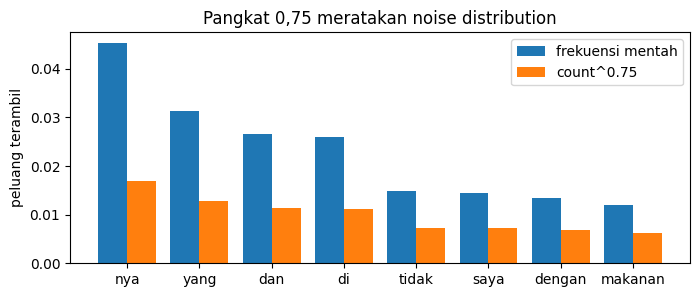

P(yang): raw 0.0313  vs  noise 0.0128   <- gunakan angka ini di Q2.3


In [11]:
assert np.isclose(sigmoid(np.array([0.0]))[0], 0.5)
assert np.allclose(sigmoid(np.array([-1000.0, 1000.0])), [0, 1])
p_noise = noise_distribution(counts)
assert np.isclose(p_noise.sum(), 1)
print("sigmoid dan noise_distribution OK")

p_raw = counts / counts.sum()
top = np.argsort(-counts)[:8]
fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(top))
ax.bar(x - 0.2, p_raw[top], 0.4, label="frekuensi mentah")
ax.bar(x + 0.2, p_noise[top], 0.4, label="count^0.75")
ax.set_xticks(x); ax.set_xticklabels([vocab[i] for i in top])
ax.set_ylabel("peluang terambil"); ax.legend(); ax.set_title("Pangkat 0,75 meratakan noise distribution")
plt.show()
print(f"P(yang): raw {p_raw[w2i['yang']]:.4f}  vs  noise {p_noise[w2i['yang']]:.4f}   <- gunakan angka ini di Q2.3")

### 3.2 Loss dan gradient (13 poin)

Implementasikan jawaban Q2.1 Anda untuk satu **batch** berisi B pasangan, masing-masing dengan K sampel negatif:

| Input | Shape | Arti |
|---|---|---|
| `vc` | (B, d) | center vector |
| `uo` | (B, d) | outside vector dari tetangga yang benar |
| `uk` | (B, K, d) | outside vector dari K sampel negatif untuk setiap pasangan |

Kembalikan loss yang **dijumlahkan** atas seluruh batch, serta gradient `d_vc` (B, d), `d_uo` (B, d), `d_uk` (B, K, d).

**Petunjuk:** skor positif adalah `(vc * uo).sum(axis=1)`, shape (B,). Skor negatif adalah `(uk * vc[:, None, :]).sum(axis=2)`, shape (B, K): `vc[:, None, :]` ber-shape (B, 1, d), sehingga di-broadcast ke semua K sampel negatif. Tidak perlu loop.

In [12]:
def neg_sampling_loss_and_grads(vc, uo, uk):
    # TODO 1: skor positif s_pos (B,) dan skor negatif s_neg (B, K)
    # TODO 2: loss = -sum(log_sigmoid(s_pos)) - sum(log_sigmoid(-s_neg))
    # TODO 3: gradient dari Q2.1, dalam bentuk batch
    # TULIS KODE ANDA DI SINI
    s_pos = (vc * uo).sum(axis=1)
    s_neg = (uk * vc[:, None, :]).sum(axis=2)
    loss = -np.sum(log_sigmoid(s_pos)) - np.sum(log_sigmoid(-s_neg))

    p = (sigmoid(s_pos) - 1.0)[:, None]
    q = (1.0 - sigmoid(-s_neg))[:, :, None]
    d_uo = p * vc
    d_uk = q * vc[:, None, :]
    d_vc = p * uo + (q * uk).sum(axis=1)
    return loss, d_vc, d_uo, d_uk

**Gradient check (sudah disediakan).** Semua relative error harus di bawah `1e-6`.

In [13]:
def grad_check(n_checks=4, h=1e-5, seed=0):
    r = np.random.default_rng(seed)
    vc, uo, uk = r.standard_normal((4, 5)), r.standard_normal((4, 5)), r.standard_normal((4, 3, 5))
    _, *grads = neg_sampling_loss_and_grads(vc, uo, uk)
    worst = 0
    for name, X, G in zip(["vc", "uo", "uk"], [vc, uo, uk], grads):
        for _ in range(n_checks):
            idx = tuple(int(r.integers(s)) for s in X.shape)
            old = X[idx]
            X[idx] = old + h; Lp = neg_sampling_loss_and_grads(vc, uo, uk)[0]
            X[idx] = old - h; Lm = neg_sampling_loss_and_grads(vc, uo, uk)[0]
            X[idx] = old
            num = (Lp - Lm) / (2 * h)
            rel = abs(num - G[idx]) / max(1e-12, abs(num) + abs(G[idx]))
            worst = max(worst, rel)
            print(f"{name}{list(idx)}  numerical={num:+.6f}  analytic={G[idx]:+.6f}  rel.err={rel:.1e}")
    print("LULUS" if worst < 1e-6 else "GAGAL: periksa kembali gradient Anda")

grad_check()

vc[3, 4]  numerical=+0.780028  analytic=+0.780028  rel.err=6.3e-11
vc[0, 4]  numerical=-0.622381  analytic=-0.622381  rel.err=8.2e-11
vc[3, 1]  numerical=+0.991138  analytic=+0.991138  rel.err=1.6e-11
vc[1, 2]  numerical=+3.591230  analytic=+3.591230  rel.err=2.5e-12
uo[2, 2]  numerical=+0.821176  analytic=+0.821176  rel.err=1.3e-11
uo[0, 4]  numerical=+0.398834  analytic=+0.398834  rel.err=3.0e-11
uo[2, 0]  numerical=+0.220134  analytic=+0.220134  rel.err=2.5e-11
uo[3, 3]  numerical=-0.048370  analytic=-0.048370  rel.err=8.7e-11
uk[0, 1, 2]  numerical=+0.399816  analytic=+0.399816  rel.err=6.1e-11
uk[0, 2, 3]  numerical=+0.075870  analytic=+0.075870  rel.err=7.0e-10
uk[1, 0, 0]  numerical=+0.344981  analytic=+0.344981  rel.err=1.4e-10
uk[3, 0, 2]  numerical=-0.178820  analytic=-0.178820  rel.err=1.0e-10
LULUS


### 3.3 Training (5 poin)

Satu perbedaan dari office hours: di sana kita **merata-ratakan** gradient atas batch. word2vec yang asli justru melakukan satu langkah SGD **per pasangan** dengan learning rate sekitar 0,025, itulah sebabnya loss di atas berupa **jumlah**. Jika dirata-ratakan atas 512 pasangan, setiap langkah menjadi 512× lebih kecil dan model hampir tidak bergerak.

Seperti di office hours, kata yang sama bisa muncul berkali-kali dalam satu batch (sebagai center word, tetangga yang benar, atau sampel negatif), sehingga update harus diakumulasi dengan `np.add.at`. Perhatikan bahwa `U` di-update dua kali: sekali untuk tetangga yang benar dan sekali untuk sampel negatif.

In [14]:
def train_word2vec(corpus_ids, counts, d=100, window=3, K=5, lr0=0.025, epochs=3, B=512, seed=0):
    rng = np.random.default_rng(seed)
    V = len(counts)
    pairs = make_pairs(corpus_ids, window)
    p_noise = noise_distribution(counts)
    Vc = (rng.random((V, d)) - 0.5) / d      # center vector acak yang kecil
    U = np.zeros((V, d))                     # outside vector dimulai dari nol
    steps = epochs * len(pairs) // B
    history, t0 = [], time.time()
    print(f"{len(pairs):,} pasangan, {steps:,} langkah")
    for step in range(steps):
        lr = lr0 * (1 - step / steps) + 1e-4  # linear decay, seperti pada word2vec asli
        batch = pairs[rng.integers(len(pairs), size=B)]
        c, o = batch[:, 0], batch[:, 1]
        neg = rng.choice(V, size=(B, K), p=p_noise)
        loss, d_vc, d_uo, d_uk = neg_sampling_loss_and_grads(Vc[c], U[o], U[neg])
        # TODO: tiga update SGD dengan np.add.at:
        #   Vc pada baris c     dengan d_vc
        #   U  pada baris o     dengan d_uo
        #   U  pada baris neg   dengan d_uk   (petunjuk: neg.ravel() dan d_uk.reshape(-1, d))
        # TULIS KODE ANDA DI SINI
        np.add.at(Vc, c, -lr * d_vc)
        np.add.at(U, o, -lr * d_uo)
        np.add.at(U, neg.ravel(), -lr * d_uk.reshape(-1, d))
        history.append(loss / B)
        if step % (steps // 5) == 0:
            print(f"  langkah {step:6d}  loss {np.mean(history[-200:]):.3f}  ({time.time() - t0:.0f} detik)")
    return Vc, U, history

1,656,662 pasangan, 9,707 langkah
  langkah      0  loss 4.159  (0 detik)
  langkah   1941  loss 2.520  (22 detik)
  langkah   3882  loss 2.419  (44 detik)
  langkah   5823  loss 2.377  (67 detik)
  langkah   7764  loss 2.349  (91 detik)
  langkah   9705  loss 2.336  (115 detik)


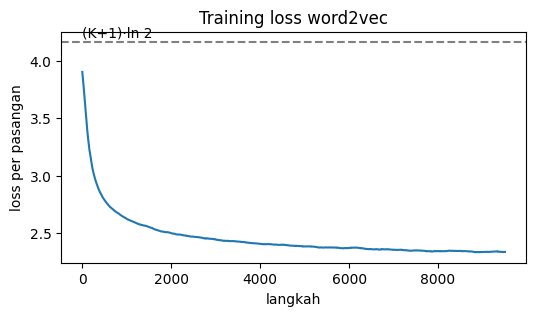

In [15]:
E_w2v, U_w2v, history = train_word2vec(corpus_ids, counts)

plt.figure(figsize=(6, 3))
plt.plot(np.convolve(history, np.ones(200) / 200, mode="valid"))
plt.axhline(6 * np.log(2), ls="--", c="gray"); plt.text(0, 6 * np.log(2) + 0.05, "(K+1)·ln 2")
plt.xlabel("langkah"); plt.ylabel("loss per pasangan"); plt.title("Training loss word2vec"); plt.show()

**Q3.1 (dinilai sebagai bagian dari Bagian 3)** Loss dimulai hampir tepat di $(K + 1)\ln 2 ≈ 4{,}16$. Jelaskan mengapa, berdasarkan cara `U` diinisialisasi.

**Jawaban Anda:** Karena matriks $U$ diinisialisasi dengan nilai nol seluruhnya (U = np.zeros(...)), maka setiap vektor konteks positif ($u_o$) dan sampel negatif ($u_{w_k}$) bernilai nol ($\mathbf{0}$).

---
## Bagian 4: Eksplorasi vector (15 poin)

### 4.1 Nearest neighbors: PPMI vs. word2vec

enak       PPMI:     ['rasanya', 'nya', 'mantap', 'rasa', 'lezat', 'dan']
           word2vec: ['mantap', 'sedap', 'enak-enak', 'juara', 'yummy', 'super']
mahal      PPMI:     ['harga', 'relatif', 'tapi', 'murah', 'lumayan', 'rata-rata']
           word2vec: ['sepadan', 'relatif', 'murah', 'menguras', 'setimpal', 'kemahalan']
bandung    PPMI:     ['kota', 'di', 'restoran', 'dago', 'ini', 'terletak']
           word2vec: ['lembang', 'kuliner', 'kota', 'kembang', 'dago', 'suis']
pelayanan  PPMI:     ['ramah', 'baik', 'cepat', 'memuaskan', 'servis', 'sopan']
           word2vec: ['ramah', 'layanan', 'servis', 'staf', 'cepat', 'pelayan']
kecewa     PPMI:     ['menyesal', 'merasa', 'keputusan', 'aku', 'jnt', 'senang']
           word2vec: ['muak', 'pelanggan', 'merasa', 'buruk', 'bosan', 'benci']
nasi       PPMI:     ['goreng', 'ayam', 'timbel', 'asin', 'bakar', 'enak']
           word2vec: ['ayam', 'sup', 'liwet', 'kepiting', 'timbel', 'goreng']
kopi       PPMI:     ['minum', 'latte', 'min

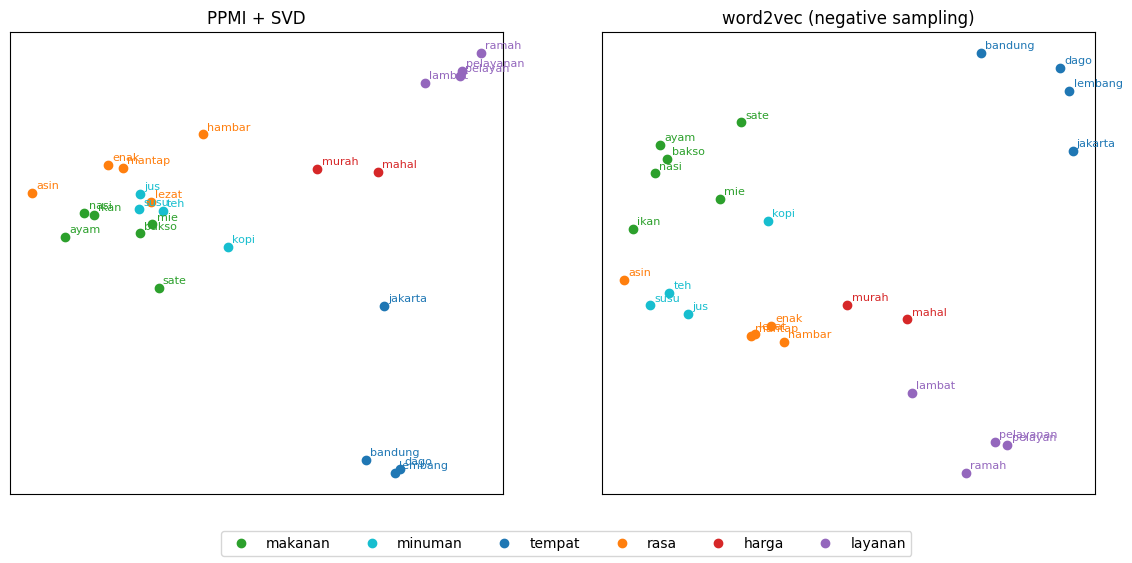

In [16]:
for w in PROBE_WORDS:
    print(f"{w:10s} PPMI:     {nearest(E_ppmi, w, w2i, vocab)}")
    print(f"{'':10s} word2vec: {nearest(E_w2v, w, w2i, vocab)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_words(axes[0], E_ppmi, w2i, "PPMI + SVD")
plot_words(axes[1], E_w2v, w2i, "word2vec (negative sampling)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in GROUP_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=6); plt.show()

**Q4.1 (4 poin)** Lihat nearest neighbors dari *enak* dan *kopi* di kedua model. Satu model cenderung menghasilkan kata yang **muncul di samping** kata yang diuji, sedangkan model lainnya menghasilkan kata yang **bisa menggantikannya**. Mana yang mana? Berikan dua contoh dari output Anda.

**Jawaban Anda:** PPMI cenderung menghasilkan kata yang muncul di samping, sedangkan Word2Vec cenderung menghasilkan kata yang bisa

Kata enak:

PPMI: Menghasilkan kata yang sering berdampingan/muncul bersamaan seperti 'rasanya' dan 'dan' (misal: "rasanya enak", "enak dan...").

Word2Vec: Menghasilkan kata-kata sifat/sinonim yang bisa menggantikan peran kata enak seperti 'sedap', 'yummy', dan 'mantap'.

Kata kopi:

PPMI: Menghasilkan kata yang mendampingi dalam konteks kalimat seperti 'minum' dan 'segelas' (misal: "minum kopi", "segelas kopi").

Word2Vec: Menghasilkan sesama kategori minuman yang dapat menggantikan posisi kata kopi dalam kalimat seperti 'teh', 'beer', dan 'bir'
### 4.2 Analogi

In [18]:
ANALOGIES = [
    ("makan", "makanan", "minum"),        # kata kerja -> kata benda dengan akhiran -an
    ("makanan", "lezat", "pelayanan"),    # apa padanan "lezat" untuk layanan?
    ("ayam", "goreng", "ikan"),
    ("bandung", "dago", "jakarta"),       # Dago adalah kawasan di Bandung
    ("mahal", "murah", "besar"),          # arah antonim?
]
for a, b, c in ANALOGIES:
    print(f"{a} : {b} :: {c} : ?   word2vec → {analogy(E_w2v, a, b, c, w2i, vocab)}")

# TODO (Q4.2): tambahkan dua analogi buatan Anda sendiri lalu jalankan
MY_ANALOGIES = [
    ("es", "dingin", "sup"),
    ("minum", "minuman", "goreng"),
]
for a, b, c in MY_ANALOGIES:
    print(f"[milik saya] {a} : {b} :: {c} : ?   → {analogy(E_w2v, a, b, c, w2i, vocab)}")

makan : makanan :: minum : ?   word2vec → ['minuman', 'berat', 'cemilan', 'penutup']
makanan : lezat :: pelayanan : ?   word2vec → ['sopan', 'memuaskan', 'ramah', 'layanan']
ayam : goreng :: ikan : ?   word2vec → ['timbel', 'pepes', 'liwet', 'sup']
bandung : dago :: jakarta : ?   word2vec → ['tol', 'terminal', 'turun', 'pintu']
mahal : murah :: besar : ?   word2vec → ['buah', 'mengenyangkan', 'ukuran', 'disediakan']
[milik saya] es : dingin :: sup : ?   → ['cuaca', 'hawa', 'terkesan', 'sejuk']
[milik saya] minum : minuman :: goreng : ?   → ['bebek', 'lotek', 'bakso', 'kepiting']


**Q4.2 (4 poin)** Dari kelima analogi, mana yang berhasil dan mana yang gagal? Untuk **satu** analogi yang gagal, jelaskan mengapa corpus ini tidak dapat mendukungnya. Kemudian laporkan dua analogi buatan Anda sendiri dan apakah keduanya berhasil.

**Jawaban Anda:**
Berhasil: makan : makanan :: minum : ? (menghasilkan 'minuman') dan makanan : lezat :: pelayanan : ? (menghasilkan kata sifat pelayanan seperti 'sopan', 'memuaskan', 'ramah').

Gagal: bandung : dago :: jakarta : ? (menghasilkan 'tol', 'terminal'), mahal : murah :: besar : ? (menghasilkan 'buah', 'mengenyangkan'), serta ayam : goreng :: ikan : ? (menghasilkan 'timbel', 'pepes').

Pada analogi bandung : dago :: jakarta : ?, kata Jakarta di dalam korpus ulasan kuliner lokal ini lebih dominan muncul pada konteks perjalanan antar-kota (seperti "lewat tol", "turun di terminal"). Hal ini membuat vektor Jakarta bergeser ke area transportasi lalu lintas alih-alih memetakan nama kawasan/area di dalamnya

es : dingin :: sup : ? $\rightarrow$ Gagal, karena menghasilkan kata suasana seperti 'cuaca', 'hawa', dan 'sejuk', bukan kata suhu berlawanan (panas/hangat).   

minum : minuman :: goreng : ? $\rightarrow$ Gagal, karena menghasilkan daftar nama hidangan yang digoreng seperti 'bebek', 'lotek', dan 'bakso', bukan bentuk kata benda pembentukan imbuhan (gorengan).

Evaluasi: Kedua analogi buatan tidak berhasil karena model Word2Vec pada korpus ini cenderung mengelompokkan kata berdasarkan asosiasi jenis makanan dan deskripsi umum lingkungan, bukan hubungan gramatis atau pergeseran sifat abstrak

### 4.3 Antonim

In [19]:
PAIRS = [("enak", "lezat"), ("mahal", "murah"), ("besar", "kecil"), ("panas", "dingin"), ("bagus", "jelek"), ("enak", "buruk")]
for a, b in PAIRS:
    if a in w2i and b in w2i:
        print(f"cos({a}, {b}) = {cosine(E_w2v, a, b, w2i):.2f}")

cos(enak, lezat) = 0.79
cos(mahal, murah) = 0.84
cos(besar, kecil) = 0.81
cos(panas, dingin) = 0.83
cos(bagus, jelek) = 0.62
cos(enak, buruk) = 0.54


**Q4.3 (4 poin)** Bandingkan cos(*mahal*, *murah*) dengan cos(*enak*, *lezat*). Jelaskan hasilnya menggunakan distributional hypothesis. Mengapa ini menjadi masalah jika kita ingin memakai vector ini untuk **sentiment** classification?

**Jawaban Anda:**
Perbandingan Nilai Cosine Similarity:
Nilai $\cos(\text{mahal}, \text{murah}) = 0,84$ ternyata lebih tinggi daripada pasangan sinonim $\cos(\text{enak}, \text{lezat}) = 0,79$.

Distributional hypothesis menyatakan bahwa kata-kata yang muncul dalam lingkungan konteks kalimat serupa akan memiliki representasi vektor yang berdekatan. Pasangan antonim seperti mahal dan murah sering kali muncul dalam struktur kalimat ulasan yang identik (misalnya: "harganya tergolong [mahal/murah]" atau "tempatnya [mahal/murah]"). Karena kata-kata di sekitarnya (context words) sangat mirip, Word2Vec memetakan kedua vektor tersebut sangat dekat satu sama lain

Dalam sentiment classification, kata mahal (berkonotasi negatif) dan murah (berkonotasi positif) memiliki polaritas yang bertolak belakang. Karena Word2Vec memberikan nilai vektor yang hampir sama ($\text{similarity} = 0,84$), model classifier akan kesulitan memisahkan mana teks ber sentimen positif dan mana yang negatif, sehingga menurunkan akurasi klasifikasi.



### 4.4 Bahasa siapa yang direpresentasikan?

In [20]:
for w in ["bandung", "jakarta", "surabaya", "malang"]:
    if w in w2i:
        print(f"{w:9s} (jumlah {int(counts[w2i[w]]):5d}) → {nearest(E_w2v, w, w2i, vocab)}")

bandung   (jumlah  1723) → ['lembang', 'kuliner', 'kota', 'kembang', 'dago', 'suis']
jakarta   (jumlah   205) → ['tol', 'telkom', 'komisi', 'haji', 'nomor', 'bekasi']
surabaya  (jumlah    38) → ['polling', 'alur', 'ditaruh', 'logika', 'holycow', 'menangis']
malang    (jumlah    53) → ['karapitan', 'brebes', 'suharti', 'rica', 'bakmi', 'kejaksaan']


**Q4.4 (3 poin)** Bandingkan nearest neighbors dan jumlah kemunculan *bandung* dengan kota-kota lain. Corpus ini sebagian besar berisi teks jenis apa? Sebutkan satu konsekuensinya bagi siapa pun yang memakai vector ini untuk task atau wilayah lain, dan kaitkan dengan responsible AI.

**Jawaban Anda:**
Jumlah Kemunculan: Kata bandung muncul sebanyak 1.723 kali, jauh mendominasi dibandingkan jakarta (205 kali), malang (53 kali), dan surabaya (38 kali)

Kata bandung memiliki neighbors yang sangat spesifik dan relevan dengan topik kuliner serta tempat (lembang, kuliner, dago, suis). Sebaliknya, kota lain menghasilkan kata-kata acak/derau yang tidak relevan (seperti polling dan kejaksaan) akibat frekuensi kemunculannya yang sangat rendah.

Korpus ini sebagian besar berisi ulasan kuliner dan pariwisata lokal yang terpusat di wilayah Bandung.

Vektor ini mengalami geographic bias dan domain bias. Jika dipaksa untuk digunakan pada tugas NLP di luar domain kuliner Bandung atau untuk wilayah lain, kinerjanya akan buruk karena vektor kata untuk kota/entitas lain tidak memiliki pemaknaan semantik yang akurat.

Hal ini berkaitan erat dengan isu bias representasi. Menggunakan model yang dilatih pada korpus ini untuk skala nasional dapat memicu hasil keputusan yang tidak adil atau diskriminatif terhadap kelompok, wilayah, dan entitas yang kurang terwakili. Prinsip Responsible AI mewajibkan transparansi mengenai keterbatasan dataset serta audit bias sebelum menyebarkan model ke pengguna luas.

---
## Bagian 5: Sentiment classification bahasa Indonesia (25 poin)

**Task:** klasifikasikan setiap ulasan SmSA sebagai *positive*, *neutral*, atau *negative*.

**Metrik:** macro-F1 (metrik IndoNLU): F1 dari setiap kelas, lalu dirata-ratakan. Sekitar 58% data training berlabel positive, sehingga accuracy akan menguntungkan model yang mengabaikan kelas neutral.

**Protokol:** bandingkan semua sistem pada **validation set**. Sentuh **test set** tepat **satu kali**, di bagian paling akhir, hanya untuk sistem final yang Anda pilih.

**Representasi kalimat:** cara paling sederhana untuk mengubah sebuah ulasan menjadi satu vector adalah **merata-ratakan vector dari kata-katanya**. Classifier logistic regression kemudian dilatih pada rata-rata tersebut.

### 5.1 Sentence embedding (5 poin)

In [21]:
def sentence_embedding(tokens, E, w2i):
    # TODO: kembalikan rata-rata E[w2i[w]] untuk semua token yang ada di w2i.
    # Jika tidak ada satu pun token di vocabulary, kembalikan vector nol berukuran E.shape[1].
    # TULIS KODE ANDA DI SINI
  valid_vecs = [E[w2i[w]] for w in tokens if w in w2i]
  if not valid_vecs:
    return np.zeros(E.shape[1], dtype=E.dtype)

  return np.mean(valid_vecs, axis=0)

In [22]:
assert np.allclose(sentence_embedding(["a", "b", "zzz"], np.array([[1.0, 0], [3.0, 2]]), {"a": 0, "b": 1}), [2, 1])
assert np.allclose(sentence_embedding(["zzz"], np.ones((2, 3)), {"a": 0}), 0)
print("sentence_embedding OK")

def featurize(texts, E, w2i, tokenizer=tokenize):
    return np.array([sentence_embedding(tokenizer(t), E, w2i) for t in texts])

def evaluate(Xtr, Xva):
    clf = LogisticRegression(max_iter=3000, C=10).fit(Xtr, train_labels)
    pred = clf.predict(Xva)
    return f1_score(val_labels, pred, average="macro"), accuracy_score(val_labels, pred), clf, pred

sentence_embedding OK


### 5.2 Membandingkan representasi (sudah disediakan, lalu didiskusikan)

* **majority**: selalu memprediksi *positive*
* **random**: vector acak untuk setiap kata (seberapa besar tambahan dari vector yang *dipelajari*?)
* **raw SVD**, **PPMI SVD**, **word2vec**: vector Anda dari Bagian 1 dan 3
* **TF-IDF**: baseline bag-of-words klasik dengan unigram dan bigram, tanpa word vector sama sekali

sistem       val macro-F1  val acc
majority            0.246    0.583
random              0.587    0.730
raw SVD             0.800    0.839
PPMI SVD            0.814    0.849
word2vec            0.785    0.833
TF-IDF              0.843    0.888


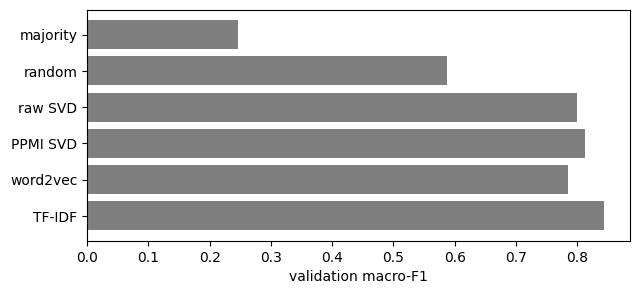

In [23]:
results, systems = {}, {}
maj = ["positive"] * len(val_labels)
results["majority"] = (f1_score(val_labels, maj, average="macro"), accuracy_score(val_labels, maj))

rng = np.random.default_rng(0)
for name, E in [("random", rng.standard_normal((V, 100))), ("raw SVD", E_raw), ("PPMI SVD", E_ppmi), ("word2vec", E_w2v)]:
    f1, acc, clf, pred = evaluate(featurize(train_texts, E, w2i), featurize(val_texts, E, w2i))
    results[name] = (f1, acc)
    systems[name] = (clf, lambda texts, E=E: featurize(texts, E, w2i))
    if name == "word2vec":
        w2v_val_pred = pred

tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
f1, acc, clf, _ = evaluate(tfidf.fit_transform(train_texts), tfidf.transform(val_texts))
results["TF-IDF"] = (f1, acc)
systems["TF-IDF"] = (clf, tfidf.transform)

print(f"{'sistem':12s} {'val macro-F1':>12s} {'val acc':>8s}")
for name, (f1, acc) in results.items():
    print(f"{name:12s} {f1:12.3f} {acc:8.3f}")

plt.figure(figsize=(7, 3))
plt.barh(list(results), [v[0] for v in results.values()], color="tab:gray")
plt.xlabel("validation macro-F1"); plt.gca().invert_yaxis(); plt.show()

**Q5.1 (5 poin)** Urutkan sistem-sistem tersebut. (a) Seberapa besar peningkatan dari vector yang dipelajari dibandingkan vector acak? (b) Sistem mana yang menang, dan mengapa model **tanpa word vector sama sekali** bisa mengalahkan rata-rata word2vec di sini? Pikirkan apa yang hilang saat dirata-ratakan, dan ukuran corpus kita.

**Jawaban Anda:**

TF-IDF: 0,843
PPMI SVD: 0,814
raw SVD: 0,800
word2vec: 0,785
random: 0,587
majority: 0,246

Besarnya Peningkatan Vektor Terpelajar vs. Vektor Acak:
Penggunaan vektor yang dipelajari memberikan peningkatan performa sebesar 0,198 hingga 0,256 poin macro-F1 (~33,7%–43,6% peningkatan relatif) jika dibandingkan dengan representasi acak (random = 0,587, sementara word2vec = 0,785 dan TF-IDF = 0,843). Hal ini menunjukkan bahwa fitur kata yang memiliki makna statistik/semantik jauh lebih berdaya pisah dibandingkan noise acak

Sistem yang menang: TF-IDF (macro-F1 = 0,843, akurasi = 0,888)

Saat membentuk sentence embedding dengan merata-ratakan vektor Word2Vec (np.mean), sinyal dari kata-kata penentu sentimen (seperti enak, kecewa, buruk) menjadi samar karena terdistorsi oleh rata-rata vektor kata-kata netral di sekitarnya. Sementara itu, TF-IDF mempertahankan bobot spesifik tiap kata kunci dan secara otomatis menekan bobot kata yang terlalu sering muncul.

### 5.3 Error analysis (5 poin)

In [24]:
NEGATIONS = {"tidak", "tak", "kurang", "belum", "bukan", "gak", "nggak", "ga", "enggak", "gk", "tdk"}

wrong = [(t, y, p) for t, y, p in zip(val_texts, val_labels, w2v_val_pred)
         if y != p and NEGATIONS & set(t.split())]
print(f"word2vec: {sum(y != p for y, p in zip(val_labels, w2v_val_pred))} error di validation, "
      f"{len(wrong)} di antaranya mengandung kata negasi\n")
for t, y, p in wrong[:8]:
    print(f"benar={y:8s} prediksi={p:8s} | {t[:150]}")

word2vec: 211 error di validation, 98 di antaranya mengandung kata negasi

benar=neutral  prediksi=negative | meski masa kampanye sudah selesai , bukan berati habis pula upaya mengerek tingkat kedipilihan elektabilitas .
benar=negative prediksi=positive | tidak enak
benar=negative prediksi=positive | kamar nya sempit tidak ada tempat menyimpan barang malah menambah barang . by the way ini kipas2 mau diletakkan mana . mana uchiwa segede ini pula .
benar=positive prediksi=negative | tidak pernah kapok dan terus berlangganan sama pengiriman jne soal nya cepat sampai nya
benar=negative prediksi=positive | menyesal x ini . kepiting tidak bersih . gurame bau tanah . mesti banyak perbaharui qualitas makanan aneh
benar=positive prediksi=negative | terus jatuh cinta pas lihat rm di mv not today . rambut ungu nya aku suka banget . terus melihat poto dia waktu konsep apa ya , aku sampai sekarang ti
benar=positive prediksi=negative | grab tidak cuma memberi kenyamanan dalam layanan nya tetapi juga

**Q5.2 (5 poin)** Pilih **dua** contoh yang salah diklasifikasikan di atas. Untuk masing-masing, jelaskan dalam satu atau dua kalimat mengapa merata-ratakan word vector membuat model keliru.

**Jawaban Anda:**
Contoh 1: "tidak enak" (Benar: negative, Prediksi: positive)

Merata-ratakan vektor kata mengabaikan urutan kata (word order) dan cakupan negasi, sehingga vektor positif kuat milik kata "enak" mendominasi hasil rata-rata. Efek pembalik makna dari kata "tidak" menjadi hilang dan membuat model keliru memprediksinya sebagai positif.

"tidak pernah kapok dan terus berlangganan sama pengiriman jne..." (Benar: positive, Prediksi: negative)

Frasa "tidak pernah kapok" secara keseluruhan bermakna positif (puas/setia), namun metode averaging memperlakukan kata "tidak" sebagai vektor negatif mandiri. Akibatnya, kehadiran token negasi tersebut menyeret seluruh rata-rata vektor kalimat ke area negatif tanpa memahami konstruksi konteksnya.

### 5.4 Token yang sadar negasi (10 poin)

Satu perbaikan sederhana: gabungkan kata negasi dengan kata sesudahnya menjadi **satu token**, sehingga *tidak enak* menjadi *tidak_enak* dan mendapat **vector-nya sendiri**.

In [26]:
def negation_tokenize(text):
    # TODO: tokenize(text), lalu gabungkan setiap kata negasi dengan kata sesudahnya: "tidak enak" -> "tidak_enak".
    # Pasangan yang digabung dihitung sebagai satu token; lanjutkan setelahnya. Kata negasi di akhir kalimat dibiarkan apa adanya.
    # TULIS KODE ANDA DI SINI
    tokens = tokenize(text)
    result = []
    i = 0
    n = len(tokens)

    while i < n:

        if tokens[i] in NEGATIONS and i + 1 < n:
            result.append(f"{tokens[i]}_{tokens[i+1]}")
            i += 2
        else:
            result.append(tokens[i])
            i += 1

    return result


In [27]:
assert negation_tokenize("rasanya tidak enak sama sekali") == ["rasanya", "tidak_enak", "sama", "sekali"]
assert negation_tokenize("bukan tidak suka") == ["bukan_tidak", "suka"]
assert negation_tokenize("enak tidak") == ["enak", "tidak"]
print("negation_tokenize OK")

neg_tokens = [negation_tokenize(t) for t in train_texts]
vocab_n, w2i_n, counts_n, corpus_ids_n = build_vocab(neg_tokens)
print(f"vocabulary baru: {len(vocab_n)} kata, contoh:", [w for w in vocab_n if w.startswith("tidak_")][:10])

E_w2v_neg, _, _ = train_word2vec(corpus_ids_n, counts_n)
f1, acc, clf, _ = evaluate(featurize(train_texts, E_w2v_neg, w2i_n, negation_tokenize),
                           featurize(val_texts, E_w2v_neg, w2i_n, negation_tokenize))
results["word2vec + negation"] = (f1, acc)
systems["word2vec + negation"] = (clf, lambda texts: featurize(texts, E_w2v_neg, w2i_n, negation_tokenize))
print(f"\nword2vec            val macro-F1 {results['word2vec'][0]:.3f}")
print(f"word2vec + negation val macro-F1 {f1:.3f}\n")

for w in ["tidak_enak", "enak", "kurang_enak", "tidak_ramah"]:
    print(f"{w:12s} → {nearest(E_w2v_neg, w, w2i_n, vocab_n)}")

negation_tokenize OK
vocabulary baru: 4518 kata, contoh: ['tidak_ada', 'tidak_akan', 'tidak_amis', 'tidak_apa-apa', 'tidak_asik', 'tidak_asing', 'tidak_bagus', 'tidak_bakal', 'tidak_banget', 'tidak_banyak']
1,613,572 pasangan, 9,454 langkah
  langkah      0  loss 4.159  (0 detik)
  langkah   1890  loss 2.524  (19 detik)
  langkah   3780  loss 2.417  (38 detik)
  langkah   5670  loss 2.372  (57 detik)
  langkah   7560  loss 2.350  (76 detik)
  langkah   9450  loss 2.340  (95 detik)

word2vec            val macro-F1 0.785
word2vec + negation val macro-F1 0.795

tidak_enak   → ['aneh', 'rada', 'kurang_enak', 'gede', 'dikit', 'biasa-biasa']
enak         → ['mantap', 'enak-enak', 'top', 'sedap', 'kurang_enak', 'kerasa']
kurang_enak  → ['standard', 'hambar', 'tidak_istimewa', 'tidak_murah', 'tidak_mengecewakan', 'kurang_banyak']
tidak_ramah  → ['seadanya', 'excellent', 'kurang_baik', 'higienis', 'kurang_bersih', 'isna']


**Q5.3 (5 poin)** (a) Laporkan perubahan macro-F1 pada validation set. (b) Lihat nearest neighbors dari *tidak_enak*: apakah ia mendapat vector yang masuk akal? (c) Jelaskan mengapa vector yang masuk akal untuk *tidak_enak* tidak otomatis memberi peningkatan klasifikasi yang besar. Sebutkan satu keterbatasan trik ini.

**Jawaban Anda:**
Nilai macro-F1 mengalami peningkatan sebesar +0,010 (dari 0,785 pada word2vec biasa menjadi 0,795 pada word2vec + negation).

Tetangga terdekat dari tidak_enak kini didominasi oleh kata-kata bernuansa negatif atau evaluasi kurang memuaskan seperti 'aneh', 'kurang_enak', dan 'biasa-biasa'. Vektor kata ini berhasil memisahkan diri dari asosiasi kata positif 'enak'.

Meskipun vektor tidak_enak membaik, token gabungan seperti tidak_enak memiliki frekuensi kemunculan yang relatif rendah (rare words) dibandingkan token tunggal biasa. Akibatnya, pembaruan vektor saat training belum terlalu tebal dan dampaknya pada validation set secara keseluruhan terbatas.

### 5.5 Test final (sudah disediakan, jalankan sekali saja)

Pilih sistem final Anda **hanya berdasarkan validation set**, lalu jalankan sel berikutnya tepat satu kali.

In [29]:
# TODO: isi FINAL dengan nama sistem yang macro-F1 validation-nya terbaik
FINAL = "TF-IDF"  # TULIS KODE ANDA DI SINI
clf, feats = systems[FINAL]
pred = clf.predict(feats(test_texts))
print(f"FINAL = {FINAL}")
print(f"val  macro-F1 {results[FINAL][0]:.3f}")
print(f"test macro-F1 {f1_score(test_labels, pred, average='macro'):.3f}   accuracy {accuracy_score(test_labels, pred):.3f}")
print("jumlah label test:", dict(collections.Counter(test_labels)))

FINAL = TF-IDF
val  macro-F1 0.843
test macro-F1 0.744   accuracy 0.806
jumlah label test: {'negative': 204, 'positive': 208, 'neutral': 88}


**Q5.4 (5 poin)** Bandingkan macro-F1 validation dan test Anda. Lihat jumlah label di test set dibandingkan dengan training set. Apa yang menjelaskan selisihnya? Mengapa penting untuk memilih `FINAL` sebelum melihat test set?

**Jawaban Anda:**
Validation macro-F1 bernilai 0.843, sedangkan test macro-F1 mengalami penurunan menjadi 0.744 (selisih ~0.099).

Pada training set, data sangat didominasi oleh kelas positive (sekitar 58%).

Sementara pada test set, proporsi positive (208 / ~41,6%) dan negative (204 / ~40,8%) jauh lebih seimbang, dengan kelas neutral sebesar 88 (~17,6%)

Pergeseran distribusi ini (distribution shift) membuat model yang terbiasa mempelajari proporsi positive tinggi di data latih menghasilkan evaluasi yang kurang optimal pada kelas negative dan neutral di test set, sehingga menurunkan macro-F1.

Langkah ini wajib dilakukan untuk mencegah data leakage (kebocoran data evaluasi) dan kebocoran keputusan (decision-level overfitting). Test set harus tetap menjadi evaluator independen yang murni untuk mengukur daya generalisasi model pada data dunia nyata yang belum pernah dipelajari sebelumnya.


---
## Bagian 6: Refleksi (5 poin)

**Q6.1** Dalam 4–6 kalimat: apa satu hal terpenting yang ditangkap word2vec tentang makna, dan apa satu keterbatasan terbesarnya yang Anda amati di tugas ini? Model apa di kurikulum berikutnya yang menurut Anda akan mengatasi keterbatasan itu, dan bagaimana caranya?

**Jawaban Anda:**
Hal terpenting yang berhasil ditangkap oleh Word2Vec adalah keserupaan semantik berbasis konteks, di mana kata-kata dengan peran yang bisa saling menggantikan dipetakan berdekatan dalam ruang vektor. Namun, keterbatasan terbesarnya yang teramati adalah sifatnya sebagai static embedding yang mengabaikan urutan kata serta struktur negasi, sehingga metode averaging merusak sinyal sentimen kalimat. Keterbatasan ini dapat diatasi oleh model berarsitektur Transformer. BERT mengatasi masalah ini dengan menghasilkan embedding kontekstual dinamis melalui mekanisme self-attention, sehingga representasi kata akan berubah mengikuti konteks utuh kalimat dan urutan kata di sekitarnya.

---
## Bonus (+10 poin, pilih satu)

1. **Rata-rata berbobot TF-IDF:** alih-alih rata-rata biasa di `sentence_embedding`, beri bobot setiap word vector dengan nilai IDF-nya. Apakah membantu pada validation set? Mengapa bisa membantu?
2. **Subsampling kata yang sering muncul** (Mikolov dkk., 2013): buang setiap kemunculan kata *w* dengan peluang $1 - \sqrt{t / f(w)}$, dengan $t = 10^{-4}$ dan $f(w)$ frekuensi relatifnya, sebelum membuat pasangan. Bandingkan nearest neighbors dan F1 validation.
3. **Bandingkan dengan gensim:** latih `gensim.models.Word2Vec` dengan pengaturan yang sama (sg=1, negative=5, window=3, vector_size=100, min_count=5), lalu bandingkan nearest neighbors dan F1 validation dengan implementasi Anda.
4. **Gabungkan fitur:** gabungkan (concatenate) fitur TF-IDF dengan sentence embedding word2vec Anda. Apakah gabungannya mengalahkan TF-IDF saja?

Laporkan angka pada **validation set** saja.